# Serology

In [61]:
# General
import numpy as np
import pandas as pd 
import requests
import warnings
import re
import html

# Visualizations
import matplotlib.pyplot as plt
import seaborn as sns

In [62]:
df_initial = pd.read_csv("serotracker.csv")

In [63]:
df_initial.columns

Index(['estimate_name', 'study_name', 'source_name', 'publication_date',
       'source_type', 'estimate_grade', 'study_type', 'country', 'state',
       'city', 'study_inclusion_criteria', 'study_exclusion_criteria',
       'sampling_start_date', 'sampling_end_date', 'population_group', 'sex',
       'age', 'age_min', 'age_max', 'subgroup_var',
       'subgroup_specific_category', 'denominator_value',
       'serum_pos_prevalence', 'seroprev_95_ci_lower', 'seroprev_95_ci_upper',
       'dashboard_primary_estimate', 'test_adj', 'pop_adj',
       'clustering_adjustment', 'academic_primary_estimate', 'sampling_method',
       'test_name', 'test_manufacturer', 'test_type', 'specimen_type',
       'isotypes', 'antibody_target', 'test_validation', 'sensitivity',
       'specificity', 'overall_risk_of_bias', 'jbi_1', 'jbi_2', 'jbi_3',
       'jbi_4', 'jbi_5', 'jbi_6', 'jbi_7', 'jbi_8', 'jbi_9', 'first_author',
       'lead_institution', 'is_unity_aligned', 'url', 'date_created',
       'last

## Age Groups

Multiple groups -> 11316  ->  58.14 %
Children and Youth (0-17 years) -> 2122  ->  10.9 %
Adults (18-64 years) -> 4953  ->  25.45 %
Seniors (65+ years) -> 1071  ->  5.5 %
nan -> 0  ->  0.0 %


<AxesSubplot:>

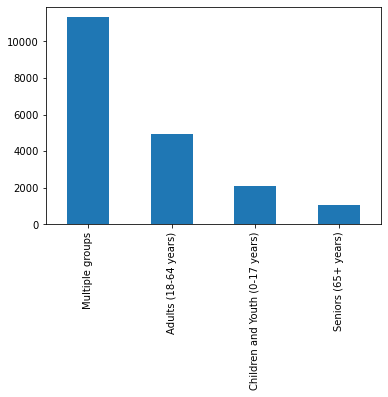

In [64]:
list_age_group = df_initial["age"].unique()

for i in list_age_group:
    print(i, "->", 
          df_initial["age"].where(df_initial["age"] == i).count(), " -> ", 
          round(df_initial["age"].where(df_initial["age"] == i).count()/df_initial["age"].count()*100, 2), "%")

df_initial['age'].value_counts().plot.bar()

## Population Groups

In [65]:
list_pop_group = df_initial["population_group"].unique()

for i in list_pop_group:
    print(i, "->", 
          df_initial["population_group"].where(df_initial["population_group"] == i).count(), " -> ", 
          round(df_initial["population_group"].where(df_initial["population_group"] == i).count()/df_initial["population_group"].count()*100, 2), "%")

Household and community samples -> 5680  ->  29.18 %
Essential non-healthcare workers -> 287  ->  1.47 %
Patients seeking care for non-COVID-19 reasons -> 341  ->  1.75 %
Representative patient population -> 30  ->  0.15 %
Residual sera -> 5228  ->  26.86 %
Blood donors -> 5488  ->  28.2 %
Persons experiencing homelessness -> 33  ->  0.17 %
Health care workers and caregivers -> 1194  ->  6.13 %
Persons living in slums -> 54  ->  0.28 %
Multiple general populations -> 110  ->  0.57 %
Contacts of COVID patients -> 60  ->  0.31 %
Pregnant or parturient women -> 318  ->  1.63 %
Multiple populations -> 219  ->  1.13 %
Non-essential workers and unemployed persons -> 120  ->  0.62 %
Students and Daycares -> 187  ->  0.96 %
Perinatal -> 13  ->  0.07 %
Assisted living and long-term care facilities -> 60  ->  0.31 %
Persons who are incarcerated -> 17  ->  0.09 %
Hospital visitors -> 12  ->  0.06 %
Tissue donor -> 1  ->  0.01 %
Family of essential workers -> 11  ->  0.06 %


In [66]:
n_df_pop_group = df_initial [ (df_initial['population_group'] == "Household and community samples") |
                              (df_initial['population_group'] == "Residual sera") |
                              (df_initial['population_group'] == "Blood donors")
                            ]

Household and community samples -> 5680  ->  29.18 %
Residual sera -> 5228  ->  26.86 %
Blood donors -> 5488  ->  28.2 %


<AxesSubplot:>

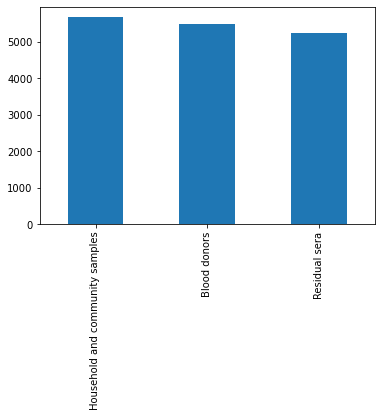

In [67]:
n_list_pop_group = n_df_pop_group["population_group"].unique()

for i in n_list_pop_group:
    print(i, "->", 
          df_initial["population_group"].where(df_initial["population_group"] == i).count(), " -> ", 
          round(df_initial["population_group"].where(df_initial["population_group"] == i).count()/df_initial["population_group"].count()*100, 2), "%")

n_df_pop_group['population_group'].value_counts().plot.bar()

## Sex

All -> 17345  ->  89.12 %
Female -> 1214  ->  6.24 %
Male -> 886  ->  4.55 %
Other -> 17  ->  0.09 %
nan -> 0  ->  0.0 %


<AxesSubplot:>

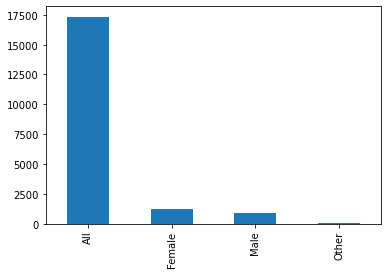

In [68]:
list_sex_group = df_initial["sex"].unique()

for i in list_sex_group:
    print(i, "->", 
          df_initial["sex"].where(df_initial["sex"] == i).count(), " -> ", 
          round(df_initial["sex"].where(df_initial["sex"] == i).count()/df_initial["sex"].count()*100, 2), "%")

df_initial['sex'].value_counts().plot.bar()

## Isotypes 

In [69]:
list_isotypes = df_initial["isotypes"].unique()

for i in list_isotypes:
    print(i, "->", 
          df_initial["isotypes"].where(df_initial["isotypes"] == i).count(), " -> ", 
          round(df_initial["isotypes"].where(df_initial["isotypes"] == i).count()/df_initial["isotypes"].count()*100, 2), "%")

['I', 'g', 'G', ',', ' ', 'I', 'g', 'M'] -> 1860  ->  10.24 %
['I', 'g', 'G'] -> 8025  ->  44.2 %
['I', 'g', 'M', ',', ' ', 'I', 'g', 'G'] -> 253  ->  1.39 %
nan -> 0  ->  0.0 %
['I', 'g', 'G', ',', ' ', 'I', 'g', 'M', ',', ' ', 'I', 'g', 'A'] -> 343  ->  1.89 %
['I', 'g', 'G', ',', ' ', 'I', 'g', 'A', ',', ' ', 'I', 'g', 'M'] -> 175  ->  0.96 %
['T', 'o', 't', 'a', 'l', ' ', 'A', 'n', 't', 'i', 'b', 'o', 'd', 'y'] -> 5959  ->  32.82 %
['I', 'g', 'A', ',', ' ', 'I', 'g', 'G', ',', ' ', 'I', 'g', 'M'] -> 70  ->  0.39 %
['I', 'g', 'G', ',', ' ', 'I', 'g', 'A', ',', ' ', 'I', 'g', 'M', ',', ' ', 'T', 'o', 't', 'a', 'l', ' ', 'A', 'n', 't', 'i', 'b', 'o', 'd', 'y'] -> 1  ->  0.01 %
['T', 'o', 't', 'a', 'l', ' ', 'A', 'n', 't', 'i', 'b', 'o', 'd', 'y', ',', ' ', 'I', 'g', 'G'] -> 290  ->  1.6 %
['I', 'g', 'A', ',', ' ', 'I', 'g', 'G'] -> 22  ->  0.12 %
['T', 'o', 't', 'a', 'l', ' ', 'A', 'n', 't', 'i', 'b', 'o', 'd', 'y', ',', ' ', 'I', 'g', 'G', ',', ' ', 'N', 'e', 'u', 't', 'r', 'a', 'l',

In [70]:
df_initial.isotypes = df_initial.isotypes.replace(["['I', 'g', 'G', ',', ' ', 'I', 'g', 'M']"], ["IgG, IgM"])
df_initial.isotypes = df_initial.isotypes.replace(["['T', 'o', 't', 'a', 'l', ' ', 'A', 'n', 't', 'i', 'b', 'o', 'd', 'y']"], ["Total Antibody"])
df_initial.isotypes = df_initial.isotypes.replace(["['I', 'g', 'G']"], ["IgG"])

In [71]:
n_df_isotypes = df_initial[ (df_initial['isotypes'] == "IgG") |
                           (df_initial['isotypes'] == "IgG, IgM") |
                           (df_initial['isotypes'] == "Total Antibody")
                         ]

IgG, IgM -> 1879  ->  10.35 %
IgG -> 8118  ->  44.71 %
Total Antibody -> 5959  ->  32.82 %


<AxesSubplot:>

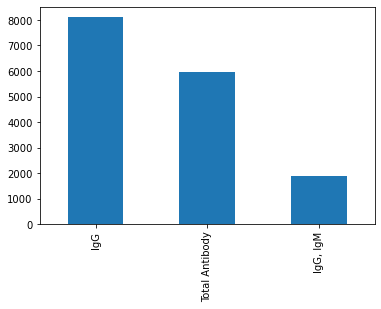

In [72]:
n_list_isotypes = n_df_isotypes["isotypes"].unique()

for i in n_list_isotypes:
    print(i, "->", 
          df_initial["isotypes"].where(df_initial["isotypes"] == i).count(), " -> ", 
          round(df_initial["isotypes"].where(df_initial["isotypes"] == i).count()/df_initial["isotypes"].count()*100, 2), "%")

n_df_isotypes['isotypes'].value_counts().plot.bar()

## Antibody Target

In [73]:
list_antibody_target = df_initial["antibody_target"].unique()

for i in list_antibody_target:
    print(i, "->", 
          df_initial["antibody_target"].where(df_initial["antibody_target"] == i).count(), " -> ", 
          round(df_initial["antibody_target"].where(df_initial["antibody_target"] == i).count()/df_initial["antibody_target"].count()*100, 2), "%")

nan -> 0  ->  0.0 %
['S', 'p', 'i', 'k', 'e'] -> 7479  ->  47.09 %
['N', 'u', 'c', 'l', 'e', 'o', 'c', 'a', 'p', 's', 'i', 'd', ' ', '(', 'N', '-', 'p', 'r', 'o', 't', 'e', 'i', 'n', ')', ',', ' ', 'S', 'p', 'i', 'k', 'e'] -> 1226  ->  7.72 %
['N', 'u', 'c', 'l', 'e', 'o', 'c', 'a', 'p', 's', 'i', 'd', ' ', '(', 'N', '-', 'p', 'r', 'o', 't', 'e', 'i', 'n', ')'] -> 4542  ->  28.6 %
['S', 'p', 'i', 'k', 'e', ',', ' ', 'N', 'u', 'c', 'l', 'e', 'o', 'c', 'a', 'p', 's', 'i', 'd', ' ', '(', 'N', '-', 'p', 'r', 'o', 't', 'e', 'i', 'n', ')'] -> 2388  ->  15.04 %
Nucleocapsid (N-protein) -> 25  ->  0.16 %
Nucleocapsid (N-protein), Spike -> 10  ->  0.06 %
['N', 'o', 't', ' ', 'r', 'e', 'p', 'o', 'r', 't', 'e', 'd', ',', ' ', 'S', 'p', 'i', 'k', 'e'] -> 12  ->  0.08 %
Spike -> 125  ->  0.79 %
['W', 'h', 'o', 'l', 'e', '-', 'v', 'i', 'r', 'u', 's', ' ', 'a', 'n', 't', 'i', 'g', 'e', 'n'] -> 18  ->  0.11 %
['S', 'p', 'i', 'k', 'e', ',', ' ', 'N', 'u', 'c', 'l', 'e', 'o', 'c', 'a', 'p', 's', 'i', 'd

In [74]:
df_initial.antibody_target = df_initial.antibody_target.replace(["['S', 'p', 'i', 'k', 'e']"], ["Spike"])
df_initial.antibody_target = df_initial.antibody_target.replace(["['N', 'u', 'c', 'l', 'e', 'o', 'c', 'a', 'p', 's', 'i', 'd', ' ', '(', 'N', '-', 'p', 'r', 'o', 't', 'e', 'i', 'n', ')']"], ["Nucleocapsid (N-protein)"])
df_initial.antibody_target = df_initial.antibody_target.replace(["['N', 'u', 'c', 'l', 'e', 'o', 'c', 'a', 'p', 's', 'i', 'd', ' ', '(', 'N', '-', 'p', 'r', 'o', 't', 'e', 'i', 'n', ')', ',', ' ', 'S', 'p', 'i', 'k', 'e']"], ["Nucleocapsid (N-protein), Spike"])
df_initial.antibody_target = df_initial.antibody_target.replace(["['S', 'p', 'i', 'k', 'e', ',', ' ', 'N', 'u', 'c', 'l', 'e', 'o', 'c', 'a', 'p', 's', 'i', 'd', ' ', '(', 'N', '-', 'p', 'r', 'o', 't', 'e', 'i', 'n', ')']"], ["Nucleocapsid (N-protein), Spike"])
df_initial.antibody_target = df_initial.antibody_target.replace(["['Spike', 'Nucleocapsid (N-protein)']"], ["Nucleocapsid (N-protein), Spike"])
df_initial.antibody_target = df_initial.antibody_target.replace(["['Nucleocapsid (N-protein)', 'Spike']"], ["Nucleocapsid (N-protein), Spike"])

In [75]:
n_df_antibody_target = df_initial[ (df_initial['antibody_target'] == "Spike") |
                                   (df_initial['antibody_target'] == "Nucleocapsid (N-protein)") |
                                   (df_initial['antibody_target'] == "Nucleocapsid (N-protein), Spike")
                                 ]

Spike -> 7604  ->  47.88 %
Nucleocapsid (N-protein), Spike -> 3640  ->  22.92 %
Nucleocapsid (N-protein) -> 4567  ->  28.76 %


<AxesSubplot:>

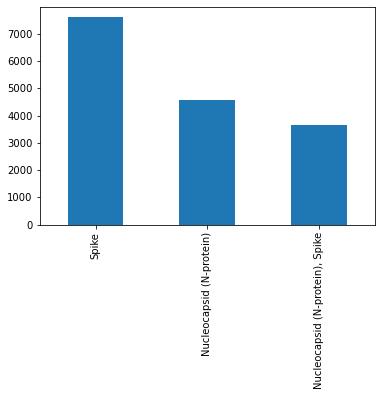

In [76]:
n_list_antibody_target = n_df_antibody_target["antibody_target"].unique()

for i in n_list_antibody_target:
    print(i, "->", 
          df_initial["antibody_target"].where(df_initial["antibody_target"] == i).count(), " -> ", 
          round(df_initial["antibody_target"].where(df_initial["antibody_target"] == i).count()/df_initial["antibody_target"].count()*100, 2), "%")

n_df_antibody_target['antibody_target'].value_counts().plot.bar()

## Risk of Bias

['Moderate'] -> 11371  ->  58.42 %
['High'] -> 5375  ->  27.62 %
['Low'] -> 2664  ->  13.69 %
['Missing'] -> 53  ->  0.27 %


<AxesSubplot:>

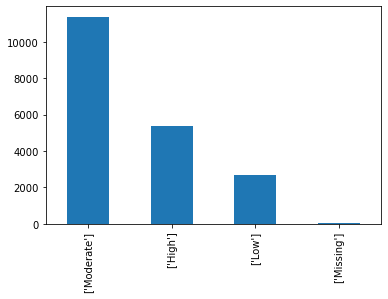

In [77]:
list_bias_group = df_initial["overall_risk_of_bias"].unique()

for i in list_bias_group:
    print(i, "->", 
          df_initial["overall_risk_of_bias"].where(df_initial["overall_risk_of_bias"] == i).count(), " -> ", 
          round(df_initial["overall_risk_of_bias"].where(df_initial["overall_risk_of_bias"] == i).count()/df_initial["overall_risk_of_bias"].count()*100, 2), "%")

df_initial['overall_risk_of_bias'].value_counts().plot.bar()

## Applying Filters

We keep the following:
 
* All age groups -
  * Multiple groups
  * Children and Youth (0-17 years)
  * Adults (18-64 years) 
  * Seniors (65+ years)


* 3 population groups - 
  * Household and community samples
  * Blood Donors
  * Residual sera
  
* All sex types - 
  * Male
  * Female 
  * Others
  * All

* 2 Risk of Bias - 
  * Moderate 
  * Low

* 3 Isotypes -
  * IgG
  * Total Antibody 
  * IgG, IgM

* 3 Antibody Targets -
  * Spike
  * Nucleocapsid (N-protein)
  * Nucleocapsid (N-protein), Spike

In [78]:
df_filtered = df_initial[
    
                         ((df_initial.population_group == "Household and community samples") |
                          (df_initial.population_group == "Blood Donors") |
                          (df_initial.population_group == "Residual sera") 
                         ) &

                         ((df_initial.overall_risk_of_bias == "['Moderate']") |
                          (df_initial.overall_risk_of_bias == "['Low']") 
                         ) &

                         ((df_initial.isotypes == "IgG, IgM") |
                          (df_initial.isotypes == "IgG") |
                          (df_initial.isotypes == "Total Antibody") 
                         ) &


                         ((df_initial.antibody_target == "Spike") |
                          (df_initial.antibody_target == "Nucleocapsid (N-protein)") |
                          (df_initial.antibody_target == "Nucleocapsid (N-protein), Spike") 
                         )

                         ]

df_filtered

,estimate_name,study_name,source_name,publication_date,source_type,estimate_grade,study_type,country,state,city,...,jbi_9,first_author,lead_institution,is_unity_aligned,url,date_created,last_modified_time,data_quality_status,zotero_citation_key,alpha_3_code
4,210220_Tirana_UniversityofMedicineandUniversit...,210220_Tirana_UniversityofMedicineandUniversit...,Rapid increase of SARS-CoV-2 seroprevalence du...,2021-02-20,Preprint,Local,Repeated cross-sectional study,Albania,NaN,Tirana,...,Yes,Genc Sulcebe,University of Medicine and University Hospital...,Unity-Aligned,https://doi.org/10.1101/2021.02.18.21251776,2021-03-21,2022-07-16,Verified,sulcebe_rapid_2021,ALB
6,220725_TiranaAndBerat_AcademyOfSciencesOfAlban...,220725_TiranaAndBerat_AcademyOfSciencesOfAlbania,Estimating the seroprevalence of SARS-CoV-2 an...,2022-07-25,Journal Article (Peer-Reviewed),Local,Cross-sectional survey,Albania,NaN,"Tirana, Berat",...,NaN,Fabian Cenko,Academy of Sciences of Albania,Unity-Aligned,https://dx.doi.org/10.7189/jogh.12.03054,2022-08-11,2022-10-20,Unverified,cenko_estimating_2022,ALB
7,220725_TiranaAndBerat_AcademyOfSciencesOfAlban...,220725_TiranaAndBerat_AcademyOfSciencesOfAlbania,Estimating the seroprevalence of SARS-CoV-2 an...,2022-07-25,Journal Article (Peer-Reviewed),Local,Cross-sectional survey,Albania,NaN,"Tirana, Berat",...,NaN,Fabian Cenko,Academy of Sciences of Albania,Unity-Aligned,https://dx.doi.org/10.7189/jogh.12.03054,2022-08-11,2022-10-20,Unverified,cenko_estimating_2022,ALB
8,220725_TiranaAndBerat_AcademyOfSciencesOfAlban...,220725_TiranaAndBerat_AcademyOfSciencesOfAlbania,Estimating the seroprevalence of SARS-CoV-2 an...,2022-07-25,Journal Article (Peer-Reviewed),Local,Cross-sectional survey,Albania,NaN,"Tirana, Berat",...,NaN,Fabian Cenko,Academy of Sciences of Albania,Unity-Aligned,https://dx.doi.org/10.7189/jogh.12.03054,2022-08-11,2022-10-20,Unverified,cenko_estimating_2022,ALB
9,220725_TiranaAndBerat_AcademyOfSciencesOfAlban...,220725_TiranaAndBerat_AcademyOfSciencesOfAlbania,Estimating the seroprevalence of SARS-CoV-2 an...,2022-07-25,Journal Article (Peer-Reviewed),Local,Cross-sectional survey,Albania,NaN,"Tirana, Berat",...,NaN,Fabian Cenko,Academy of Sciences of Albania,Unity-Aligned,https://dx.doi.org/10.7189/jogh.12.03054,2022-08-11,2022-10-20,Unverified,cenko_estimating_2022,ALB
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19441,211007_Palestine_PalestinianNationalInstituteo...,211007_Palestine_PalestinianNationalInstituteo...,Sero Prevalence of COVID-19 in Palestine in 2020,2021-10-07,Preprint,Regional,Cross-sectional survey,occupied Palestinian territory - including eas...,Gaza,NaN,...,Unclear,I Rayan,Palestinian National Institute of Public Health,Unity-Aligned,https://www.medrxiv.org/content/10.1101/2021.1...,2021-10-13,2022-07-16,Verified,rayan_seroprevalence_2021,PSE
19442,211007_Palestine_PalestinianNationalInstituteo...,211007_Palestine_PalestinianNationalInstituteo...,Sero Prevalence of COVID-19 in Palestine in 2020,2021-10-07,Preprint,Regional,Cross-sectional survey,occupied Palestinian territory - including eas...,Gaza,NaN,...,Unclear,I Rayan,Palestinian National Institute of Public Health,Unity-Aligned,https://www.medrxiv.org/content/10.1101/2021.1...,2021-10-13,2022-07-16,Verified,rayan_seroprevalence_2021,PSE
19443,211007_Palestine_PalestinianNationalInstituteo...,211007_Palestine_PalestinianNationalInstituteo...,Sero Prevalence of COVID-19 in Palestine in 2020,2021-10-07,Preprint,Regional,Cross-sectional survey,occupied Palestinian territory - including eas...,West Bank,NaN,...,Unclear,I Rayan,Palestinian National Institute of Public Health,Unity-Aligned,https://www.medrxiv.org/content/10.1101/2021.1...,2021-10-13,2022-07-16,Verified,rayan_seroprevalence_2021,PSE
19444,211007_Palestine_PalestinianNationalInstituteo...,211007_Palestine_PalestinianNationalInstituteo...,Sero Prevalence of COVID-19 in Palestine in 2020,2021-10-07,Preprint,Regional,Cross-sec

## Pivoting

In [79]:
df_final = df_filtered.filter(['age',
                               'sex',
                               'population_group', 
                               'isotypes', 
                               'antibody_target', 
                               'serum_pos_prevalence',
                               'sampling_start_date',
                               'sampling_end_date',
                               'country'], axis=1)
df_final

,age,sex,population_group,isotypes,antibody_target,serum_pos_prevalence,sampling_start_date,sampling_end_date,country
4,Adults (18-64 years),All,Household and community samples,IgG,Spike,0.4820,2020-12-21,2020-12-28,Albania
6,Multiple groups,All,Household and community samples,IgG,Spike,0.7335,2021-06-15,2021-07-15,Albania
7,Seniors (65+ years),All,Household and community samples,IgG,Spike,0.8170,2021-06-15,2021-07-15,Albania
8,Multiple groups,Female,Household and community samples,IgG,Spike,0.7525,2021-06-15,2021-07-15,Albania
9,Adults (18-64 years),All,Household and community samples,IgG,Spike,0.6888,2021-06-15,2021-07-15,Albania
...,...,...,...,...,...,...,...,...,...
19441,Multiple groups,Male,Household and community samples,IgG,Spike,0.3900,2020-12-01,2020-12-31,occupied Palestinian territory - including eas...
19442,Multiple groups,Female,Household and community samples,IgG,Spike,0.4300,2020-12-01,2020-12-31,occupied Palestinian territory - including eas...
19443,Multiple groups,All,Household and community samples,IgG,Spike,0.3800,2020-12-01,2020-12-31,occupied Palestinian territory - including eas...
19444,Multiple groups,Female,Household and community samples,IgG,Spike,0.4600,2020-12-01,2020-12-31,occupied Palestinian territory - including eas...


In [80]:
df_final_1 = df_final.pivot_table('serum_pos_prevalence', 
                                  ['sex', 'population_group', 'isotypes', 'antibody_target', 'sampling_start_date', 
                                   'sampling_end_date', 'country'], 
                                  'age')
df_final_1.reset_index( drop=False, inplace=True )

df_final_1

age,sex,population_group,isotypes,antibody_target,sampling_start_date,sampling_end_date,country,Adults (18-64 years),Children and Youth (0-17 years),Multiple groups,Seniors (65+ years)
0,All,Household and community samples,IgG,Nucleocapsid (N-protein),2020-02-01,2020-03-31,United Kingdom of Great Britain and Northern I...,NaN,0.0095,NaN,NaN
1,All,Household and community samples,IgG,Nucleocapsid (N-protein),2020-04-01,2020-04-30,United Kingdom of Great Britain and Northern I...,NaN,0.0415,NaN,NaN
2,All,Household and community samples,IgG,Nucleocapsid (N-protein),2020-04-19,2020-04-28,United States of America,0.153,NaN,0.1490,0.121
3,All,Household and community samples,IgG,Nucleocapsid (N-protein),2020-04-20,2020-04-24,United States of America,NaN,NaN,0.0048,NaN
4,All,Household and community samples,IgG,Nucleocapsid (N-protein),2020-04-25,2020-04-28,United States of America,0.034,0.0610,0.0305,0.021
...,...,...,...,...,...,...,...,...,...,...,...
1732,Other,Household and community samples,IgG,Nucleocapsid (N-protein),2020-07-01,2020-07-31,India,NaN,NaN,0.0280,NaN
1733,Other,Household and community samples,IgG,Spike,2020-05-13,2020-07-21,United States of America,NaN,NaN,0.1810,NaN
1734,Other,Household and community samples,Total Antibody,Nucleocapsid (N-protein),2021-01-08,2021-01-24,India,NaN,NaN,0.5380,NaN
1735,Other,Household and community samples,Total Antibody,Nucleocapsid (N-protein),2021-02-01,2021-05-03,United Kingdom of Great Britain and Northern I...,NaN,NaN,0.1200,NaN


In [81]:
df_final_2 = df_final.pivot_table('serum_pos_prevalence', 
                                  ['sex', 'population_group', 'isotypes', 'age', 'sampling_start_date', 
                                   'sampling_end_date', 'country'], 
                                  'antibody_target')
df_final_2.reset_index( drop=False, inplace=True )

df_final_2

antibody_target,sex,population_group,isotypes,age,sampling_start_date,sampling_end_date,country,Nucleocapsid (N-protein),"Nucleocapsid (N-protein), Spike",Spike
0,All,Household and community samples,IgG,Adults (18-64 years),2020-02-29,2020-04-29,China,NaN,0.0488,NaN
1,All,Household and community samples,IgG,Adults (18-64 years),2020-03-31,2020-05-11,Netherlands,NaN,NaN,0.0400
2,All,Household and community samples,IgG,Adults (18-64 years),2020-04-06,2020-05-09,Switzerland,NaN,NaN,0.0865
3,All,Household and community samples,IgG,Adults (18-64 years),2020-04-06,2020-06-30,Switzerland,NaN,NaN,0.0785
4,All,Household and community samples,IgG,Adults (18-64 years),2020-04-19,2020-04-28,United States of America,0.153,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2368,Other,Household and community samples,IgG,Multiple groups,2020-05-13,2020-07-21,United States of America,NaN,NaN,0.1810
2369,Other,Household and community samples,IgG,Multiple groups,2020-07-01,2020-07-31,India,0.028,NaN,NaN
2370,Other,Household and community samples,Total Antibody,Multiple groups,2020-07-22,2020-08-08,United States of America,NaN,NaN,0.0000
2371,Other,Household and community samples,Total Antibody,Multiple groups,2021-01-08,2021-01-24,India,0.538,NaN,NaN


In [82]:
 df_final_3 = df_final.pivot_table('serum_pos_prevalence', 
                                  ['sex', 'population_group', 'isotypes', 'sampling_start_date', 
                                   'sampling_end_date', 'country'], 
                                  ['antibody_target','age'])
df_final_3.reset_index( drop=False, inplace=True )

df_final_3

antibody_target    sex                 population_group        isotypes  \
age                                                                       
0                  All  Household and community samples             IgG   
1                  All  Household and community samples             IgG   
2                  All  Household and community samples             IgG   
3                  All  Household and community samples             IgG   
4                  All  Household and community samples             IgG   
...                ...                              ...             ...   
1681             Other  Household and community samples             IgG   
1682             Other  Household and community samples             IgG   
1683             Other  Household and community samples  Total Antibody   
1684             Other  Household and community samples  Total Antibody   
1685             Other  Household and community samples  Total Antibody   

antibody_target sampling_start_date sampling_end_date  \
age                                                     
0                        2019-10-01        2020-03-31   
1                        2020-02-01        2020-03-31   
2                        2020-02-29        2020-04-29   
3                        2020-03-16        2020-06-03   
4                        2020-03-31        2020-05-11   
...                             ...               ...   
1681                     2020-05-13        2020-07-21   
1682                     2020-07-01        2020-07-31   
1683                     2020-07-22        2020-08-08   
1684                     2021-01-08        2021-01-24   
1685                     2021-02-01        2021-05-03   

antibody_target                                            country  \
age                                                                  
0                United Kingdom of Great Britain and Northern I...   
1                United Kingdom of Great Britain and Northern I...   
2                                                            China   
3                United Kingdom of Great Britain and Northern I...   
4                                                      Netherlands   
...                                                            ...   
1681                                      United States of America   
1682                                                         India   
1683                                      United States of America   
1684                                                         India   
1685             United Kingdom of Great Britain and Northern I...   

antibody_target Nucleocapsid (N-protein)                                  \
age                 Adults (18-64 years) Children and Youth (0-17 years)   
0                                    NaN                             NaN   
1                                    NaN                          0.0095   
2                                    NaN                             NaN   
3                                    NaN                             NaN   
4                                    NaN                             NaN   
...                                  ...                             ...   
1681                                 NaN                             NaN   
1682                                 NaN                             NaN   
1683                                 NaN                             NaN   
1684                                 NaN                             NaN   
1685                                 NaN                             NaN   

antibody_target                                      \
age             Multiple groups Seniors (65+ years)   
0                           NaN                 NaN   
1                           NaN                 NaN   
2                           NaN                 NaN   
3                           NaN                 NaN   
4                           NaN                 NaN 

In [ ]:
df_final_3.columns = [" ".join(c).strip() for c in df_final_3.columns]
df_final_3.to_csv("Serology_data_ver_1.csv", index=False)